In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt


Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

 Logistic Regression
******************************
Accuracy : 0.8036484245439469
Precision: 0.6813933729821581
Recall   : 0.3640490240581026
F1 Score : 0.47455621301775147

 Decision Tree
******************************
Accuracy : 0.8064123825317855
Precision: 0.600088573959256
Recall   : 0.6150703586019065
F1 Score : 0.6074871105133378

Classification Report - Logistic Regression
              precision    recall  f1-score   support

           0       0.82      0.95      0.88      6842
           1       0.68      0.36      0.47      2203

    accuracy                           0.80      9045
   macro avg       0.75      0.65      0.68      9045
weighted avg       0.79      0.80      0.78      9045


Classification Report - Decision Tree
              precision    recall  f1-

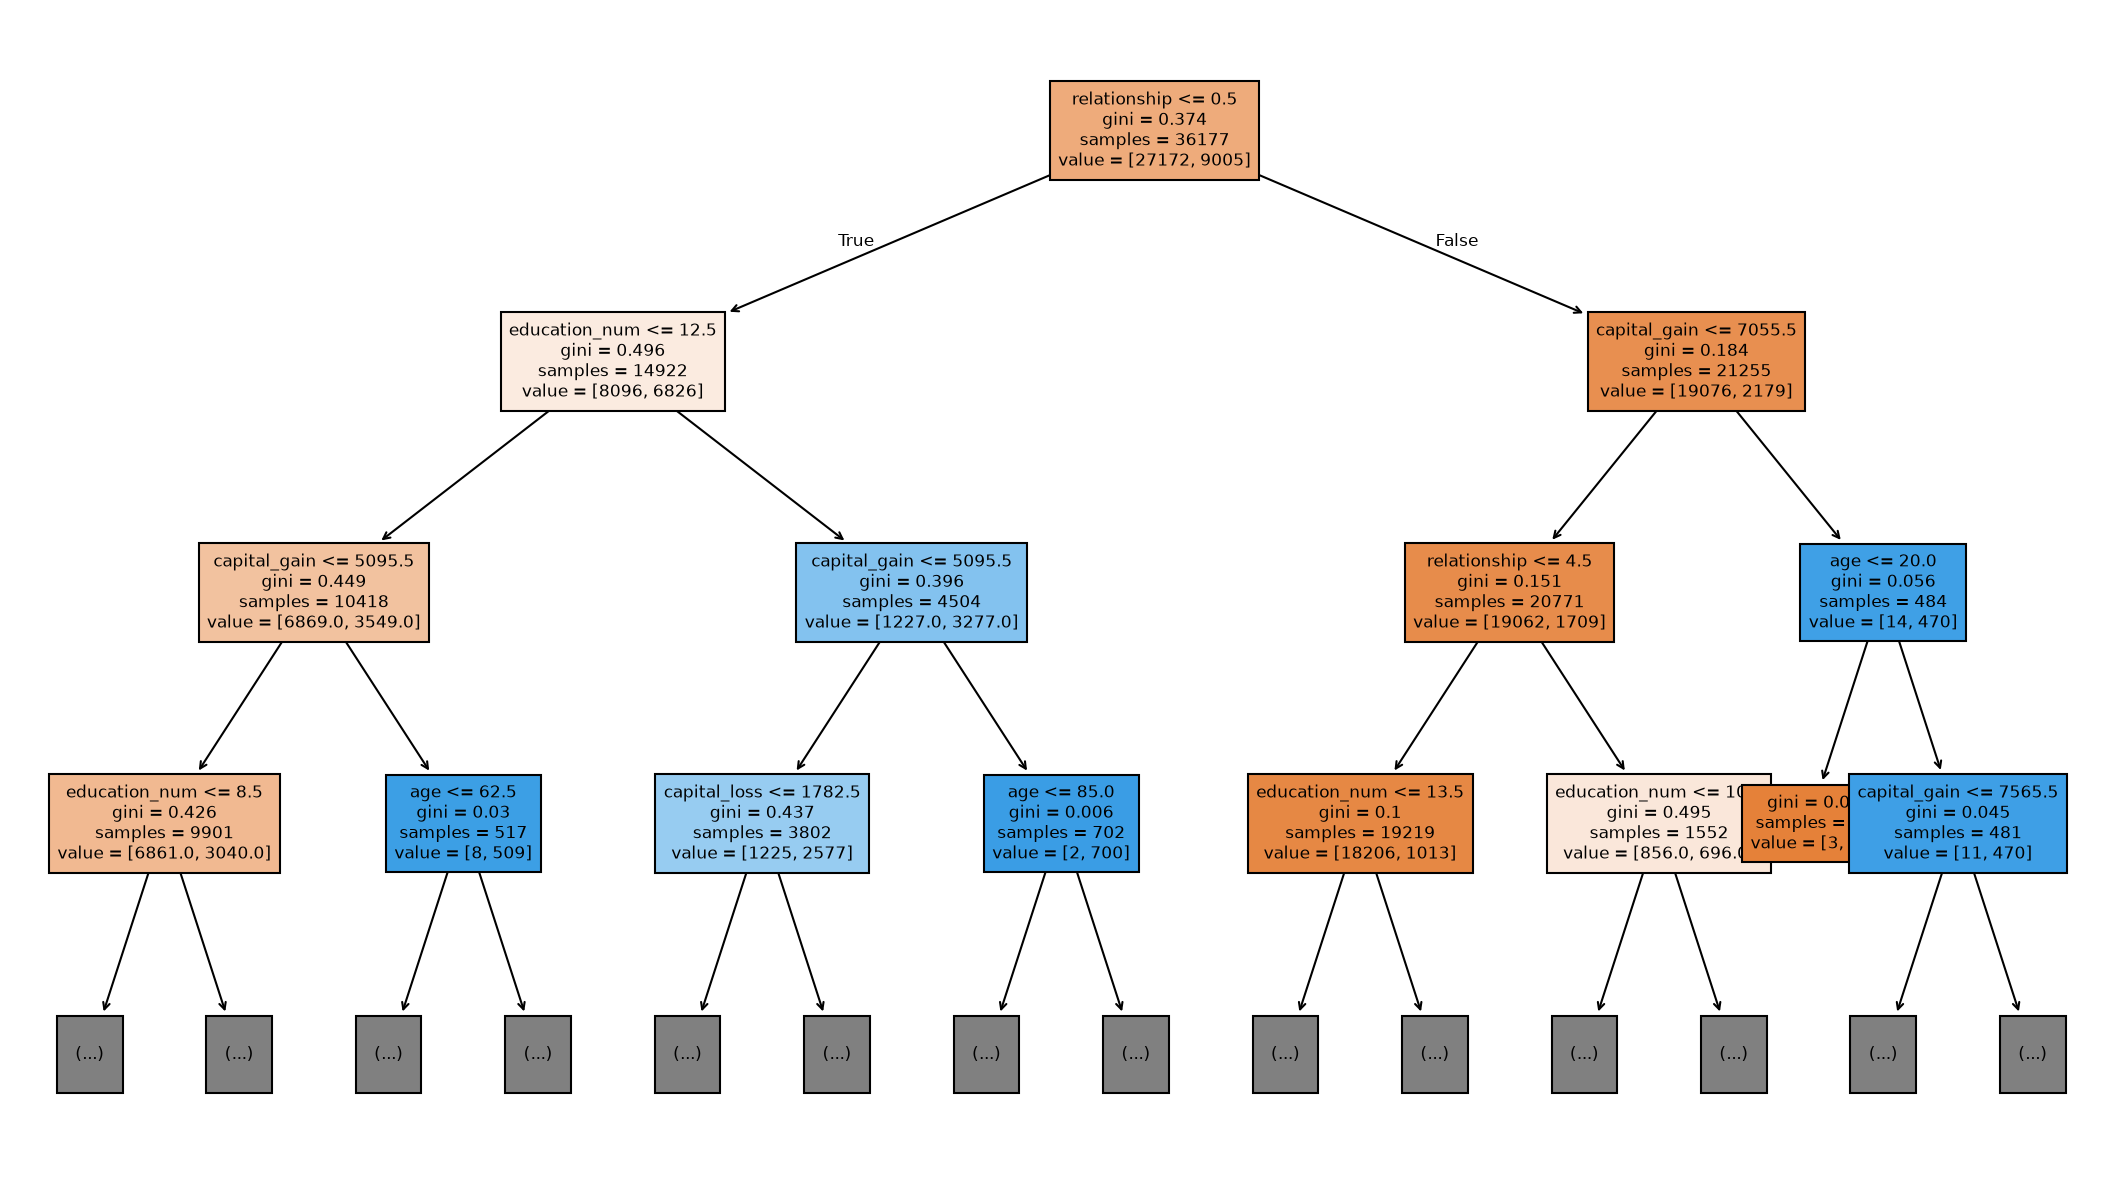

In [ ]:

df = pd.read_csv("adult.csv", header=None, skiprows=1)

df.columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income"
]


df.replace("?", np.nan, inplace=True)
df.dropna(inplace=True)

label_encoders = {}

for column in df.columns:
    if not pd.api.types.is_numeric_dtype(df[column]):
        le = LabelEncoder()
        df[column] = le.fit_transform(df[column])
        label_encoders[column] = le

print(df.columns)
X = df.drop("income", axis=1)
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

def evaluate(y_true, y_pred, model_name):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print("\n", model_name)
    print("*" * 30)
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

evaluate(y_test, lr_pred, "Logistic Regression")
evaluate(y_test, dt_pred, "Decision Tree")

print("\nClassification Report - Logistic Regression")
print(classification_report(y_test, lr_pred))

print("\nClassification Report - Decision Tree")
print(classification_report(y_test, dt_pred))

plt.figure(figsize=(18, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    filled=True,
    fontsize=8
)

plt.show()